In [13]:
import pandas as pd
import matplotlib.pyplot as plt


In [14]:
df = pd.read_csv("/Users/utkuaydin/Desktop/1milyonyol.bas.co2_mik.ton.csv", sep=";", encoding="utf-8")
print(df.head())


    YIL  AY IZMIR_METROSU KARSIYAKA_TRAMVAYI KONAK_TRAMVAYI
0  2020   1           225             190,81         132,73
1  2020   2        203,81             175,51         116,66
2  2020   3        293,09             296,36         181,33
3  2020   4        854,31            2524,38         743,58
4  2020   5        656,27            1755,99          560,6


In [15]:
print(df.columns)


Index(['YIL', 'AY', 'IZMIR_METROSU', 'KARSIYAKA_TRAMVAYI', 'KONAK_TRAMVAYI'], dtype='object')


In [16]:

for col in ["IZMIR_METROSU", "KARSIYAKA_TRAMVAYI", "KONAK_TRAMVAYI"]:
    df[col] = df[col].str.replace(",", ".").astype(float)

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   YIL                 68 non-null     int64  
 1   AY                  68 non-null     int64  
 2   IZMIR_METROSU       68 non-null     float64
 3   KARSIYAKA_TRAMVAYI  68 non-null     float64
 4   KONAK_TRAMVAYI      68 non-null     float64
dtypes: float64(3), int64(2)
memory usage: 2.8 KB


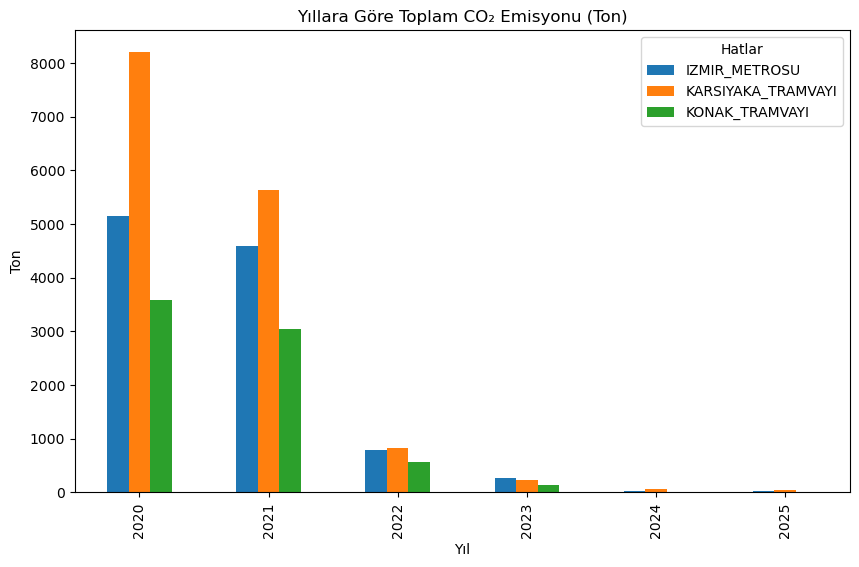

In [17]:
import matplotlib.pyplot as plt

yil_toplam = df.groupby("YIL")[["IZMIR_METROSU", "KARSIYAKA_TRAMVAYI", "KONAK_TRAMVAYI"]].sum()

yil_toplam.plot(kind="bar", figsize=(10,6))
plt.title("Yıllara Göre Toplam CO₂ Emisyonu (Ton)")
plt.ylabel("Ton")
plt.xlabel("Yıl")
plt.legend(title="Hatlar")
plt.show()


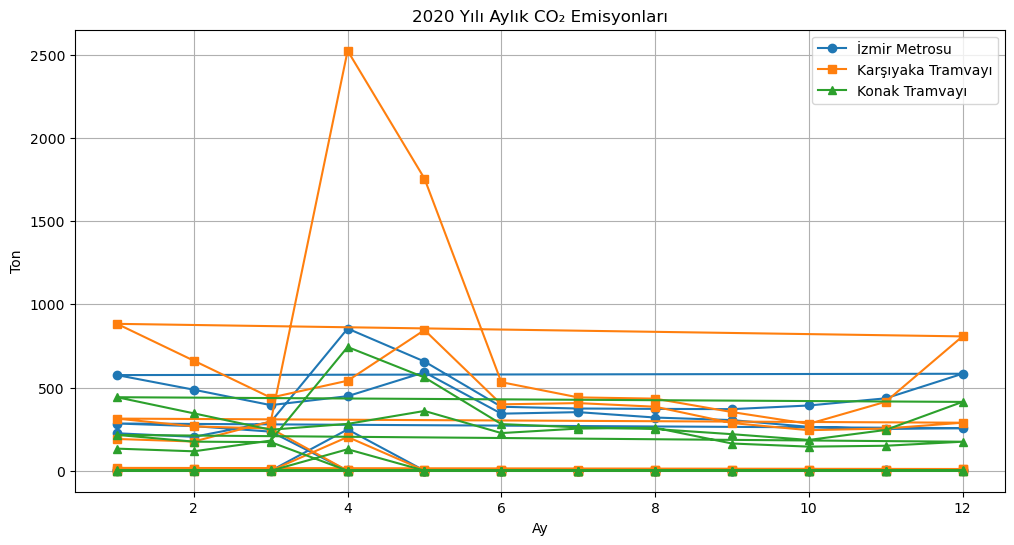

In [18]:
plt.figure(figsize=(12,6))
plt.plot(df["AY"], df["IZMIR_METROSU"], marker="o", label="İzmir Metrosu")
plt.plot(df["AY"], df["KARSIYAKA_TRAMVAYI"], marker="s", label="Karşıyaka Tramvayı")
plt.plot(df["AY"], df["KONAK_TRAMVAYI"], marker="^", label="Konak Tramvayı")
plt.title("2020 Yılı Aylık CO₂ Emisyonları")
plt.xlabel("Ay")
plt.ylabel("Ton")
plt.legend()
plt.grid(True)
plt.show()


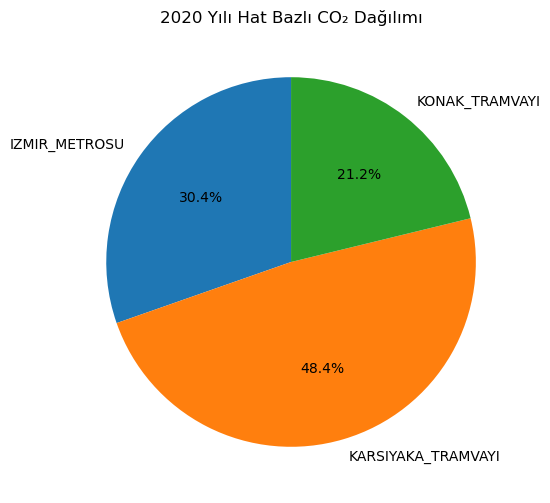

In [19]:
veri_2020 = df[df["YIL"] == 2020][["IZMIR_METROSU", "KARSIYAKA_TRAMVAYI", "KONAK_TRAMVAYI"]].sum()

plt.figure(figsize=(6,6))
plt.pie(veri_2020, labels=veri_2020.index, autopct="%1.1f%%", startangle=90)
plt.title("2020 Yılı Hat Bazlı CO₂ Dağılımı")
plt.show()


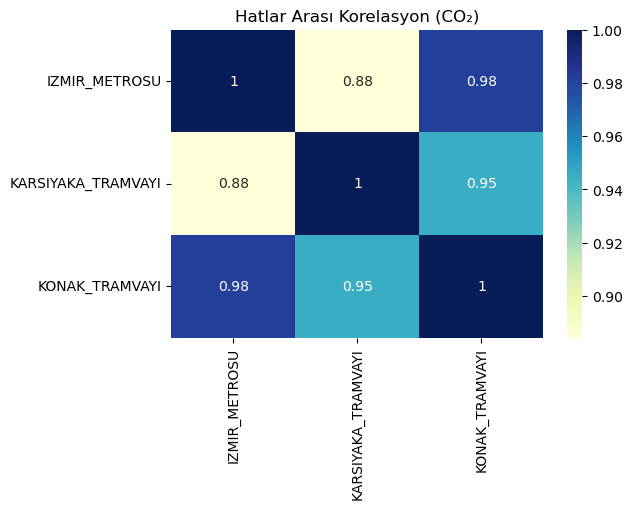

In [20]:
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(df[["IZMIR_METROSU", "KARSIYAKA_TRAMVAYI", "KONAK_TRAMVAYI"]].corr(), annot=True, cmap="YlGnBu")
plt.title("Hatlar Arası Korelasyon (CO₂)")
plt.show()


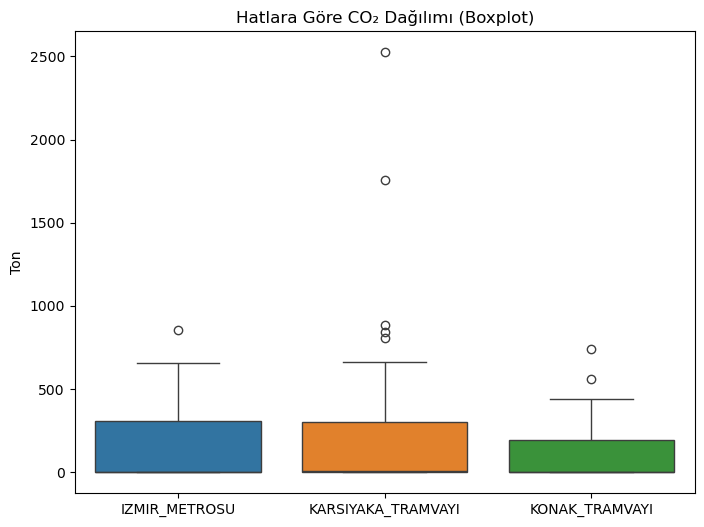

In [21]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df[["IZMIR_METROSU", "KARSIYAKA_TRAMVAYI", "KONAK_TRAMVAYI"]])
plt.title("Hatlara Göre CO₂ Dağılımı (Boxplot)")
plt.ylabel("Ton")
plt.show()


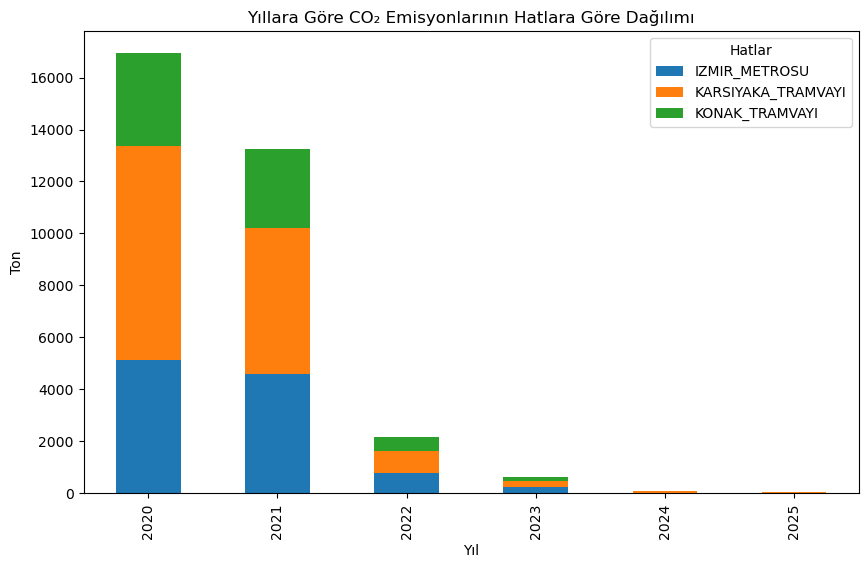

In [22]:
yil_toplam = df.groupby("YIL")[["IZMIR_METROSU","KARSIYAKA_TRAMVAYI","KONAK_TRAMVAYI"]].sum()
yil_toplam.plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Yıllara Göre CO₂ Emisyonlarının Hatlara Göre Dağılımı")
plt.ylabel("Ton")
plt.xlabel("Yıl")
plt.legend(title="Hatlar")
plt.show()